# Retail Sales KPI Dashboard + 12-Month Forecast (Superstore)

**Business question:** how is the business performing, what drives growth, and how much revenue should we plan for next year?

A KPI pack plus forecast of the kind I'd build in Power BI or Excel for a weekly business review, done here in Python so it can be reproduced:

1. **Executive KPIs**: sales, orders, customers, AOV, YoY growth
2. **Trend and seasonality**: monthly sales, decomposition
3. **Growth drivers**: category, sub-category, region and segment mix
4. **Operations**: shipping lead time by ship mode
5. **Forecast**: three models backtested on a 12-month holdout, the best one projects the next 12 months with an uncertainty band

Dataset: [Superstore Sales](https://www.kaggle.com/datasets/rohitsahoo/sales-forecasting), about 9,800 order lines from a US retailer, 2015 to 2018.

> **TL;DR**
> 1. Latest-year sales grew 20.3%, driven by order volume (+28.3%) while average order value fell 6.2% (9,800 order lines, 2015-2018).
> 2. Sales are strongly seasonal (peaks in Sep, Nov, Dec); West (+36%) and South (+31%) grew while Central slipped 3%.
> 3. Holt-Winters won the backtest (MAPE 20.8%, annual total error -1.0%) and forecasts $887k for the next 12 months (+22.9%).

In [1]:
import glob, os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})
money = mtick.FuncFormatter(lambda x, _: f"${x/1e3:,.0f}k")

def find_file(name):
    for root in ["/kaggle/input", "../input", "data", "/workspace/kaggle/data"]:
        hits = [h for h in glob.glob(os.path.join(root, "**", name), recursive=True) if "sales-forecasting" in h or root != "/workspace/kaggle/data"]
        if hits:
            return hits[0]
    raise FileNotFoundError(name)

df = pd.read_csv(find_file("train.csv"))
df["Order Date"] = pd.to_datetime(df["Order Date"], format="%d/%m/%Y")
df["Ship Date"] = pd.to_datetime(df["Ship Date"], format="%d/%m/%Y")
df = df.drop(columns=["Customer Name"])  # not needed for analysis
df["Year"] = df["Order Date"].dt.year
df["Month"] = df["Order Date"].dt.to_period("M").dt.to_timestamp()
df["LeadTime"] = (df["Ship Date"] - df["Order Date"]).dt.days
print(f"{len(df):,} order lines | {df['Order Date'].min():%d %b %Y} to {df['Order Date'].max():%d %b %Y}")
df.head(3)

9,800 order lines | 03 Jan 2015 to 30 Dec 2018


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Year,Month,LeadTime
0,1,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96,2017,2017-11-01,3
1,2,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.94,2017,2017-11-01,3
2,3,CA-2017-138688,2017-06-12,2017-06-16,Second Class,DV-13045,Corporate,United States,Los Angeles,California,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.62,2017,2017-06-01,4


## 1. Executive KPIs by year

In [2]:
yr = df.groupby("Year").agg(Sales=("Sales", "sum"), Orders=("Order ID", "nunique"), Customers=("Customer ID", "nunique"))
yr["AOV"] = yr["Sales"] / yr["Orders"]
yr["Sales YoY"] = yr["Sales"].pct_change()
yr["Orders YoY"] = yr["Orders"].pct_change()
yr["AOV YoY"] = yr["AOV"].pct_change()
yr.style.format({"Sales": "${:,.0f}", "Orders": "{:,}", "Customers": "{:,}", "AOV": "${:,.0f}",
                 "Sales YoY": "{:+.1%}", "Orders YoY": "{:+.1%}", "AOV YoY": "{:+.1%}"}, na_rep="–")

,Sales,Orders,Customers,AOV,Sales YoY,Orders YoY,AOV YoY
Year,,,,,,,
2015,"$479,856",947,589,$507,–,–,–
2016,"$459,436","1,019",567,$451,-4.3%,+7.6%,-11.0%
2017,"$600,193","1,295",635,$463,+30.6%,+27.1%,+2.8%
2018,"$722,052","1,661",690,$435,+20.3%,+28.3%,-6.2%


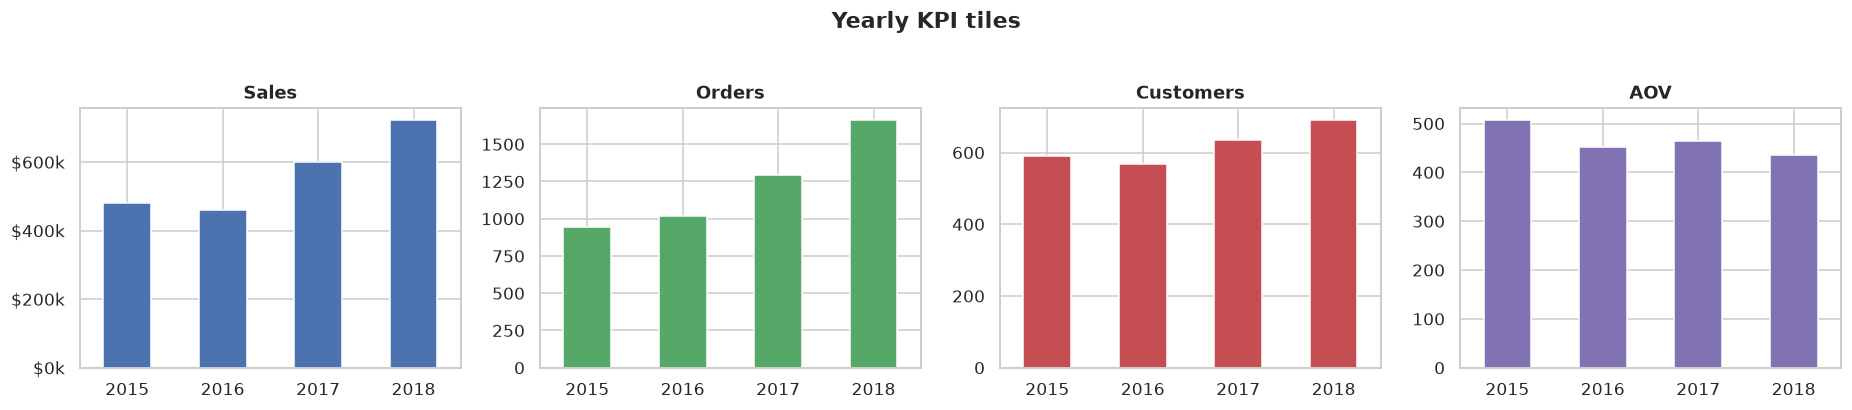

Latest year: sales +20.3%, made up of order volume +28.3% and AOV -6.2%. Growth is mainly volume-driven.


In [3]:
fig, axes = plt.subplots(1, 4, figsize=(17, 3.6))
for ax, col, c in zip(axes, ["Sales", "Orders", "Customers", "AOV"], ["#4c72b0", "#55a868", "#c44e52", "#8172b3"]):
    yr[col].plot.bar(ax=ax, color=c); ax.set_title(col); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=0)
axes[0].yaxis.set_major_formatter(money)
plt.suptitle("Yearly KPI tiles", y=1.03, fontweight="bold"); plt.tight_layout(); plt.show()
g = yr["Sales YoY"].iloc[-1]; go = yr["Orders YoY"].iloc[-1]; ga = yr["AOV YoY"].iloc[-1]
print(f"Latest year: sales {g:+.1%}, made up of order volume {go:+.1%} and AOV {ga:+.1%}. Growth is mainly {'volume' if abs(go) > abs(ga) else 'basket size'}-driven.")

## 2. Trend and seasonality

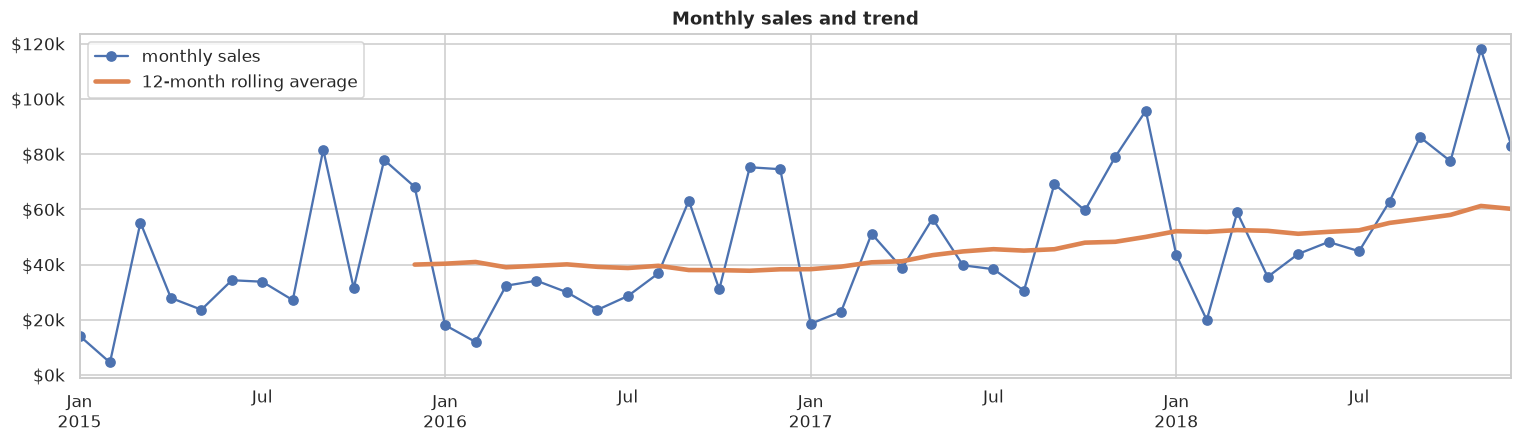

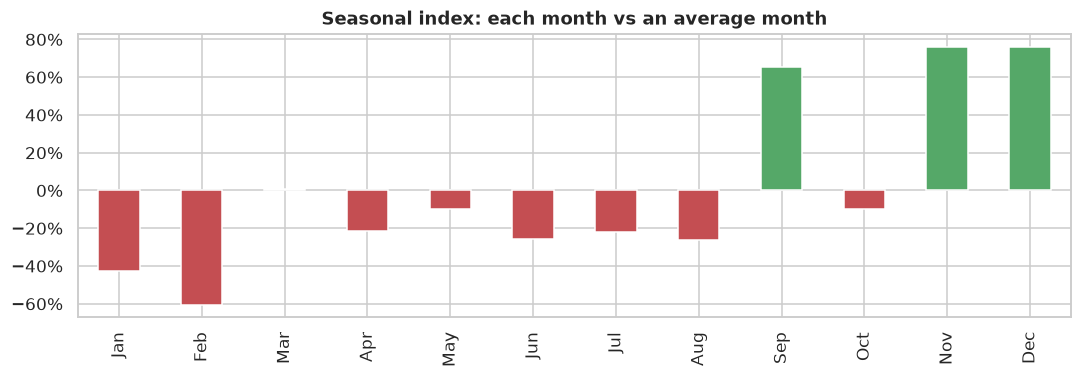

Peak months: Dec, Nov, Sep. Weakest: Feb, Jan.


In [4]:
monthly = df.groupby("Month")["Sales"].sum().asfreq("MS")
fig, ax = plt.subplots(figsize=(14, 4.2))
monthly.plot(ax=ax, marker="o", label="monthly sales")
monthly.rolling(12).mean().plot(ax=ax, lw=3, label="12-month rolling average")
ax.yaxis.set_major_formatter(money); ax.set_title("Monthly sales and trend"); ax.set_xlabel(""); ax.legend()
plt.tight_layout(); plt.show()

dec = seasonal_decompose(monthly, model="multiplicative", period=12)
seas = dec.seasonal[:12]; seas.index = seas.index.strftime("%b")
fig, ax = plt.subplots(figsize=(10, 3.6))
(seas - 1).plot.bar(ax=ax, color=np.where(seas > 1, "#55a868", "#c44e52"))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax.set_title("Seasonal index: each month vs an average month"); ax.set_xlabel("")
plt.tight_layout(); plt.show()
print(f"Peak months: {', '.join(seas.sort_values(ascending=False).index[:3])}. Weakest: {', '.join(seas.sort_values().index[:2])}.")

## 3. Growth drivers: category, region and segment

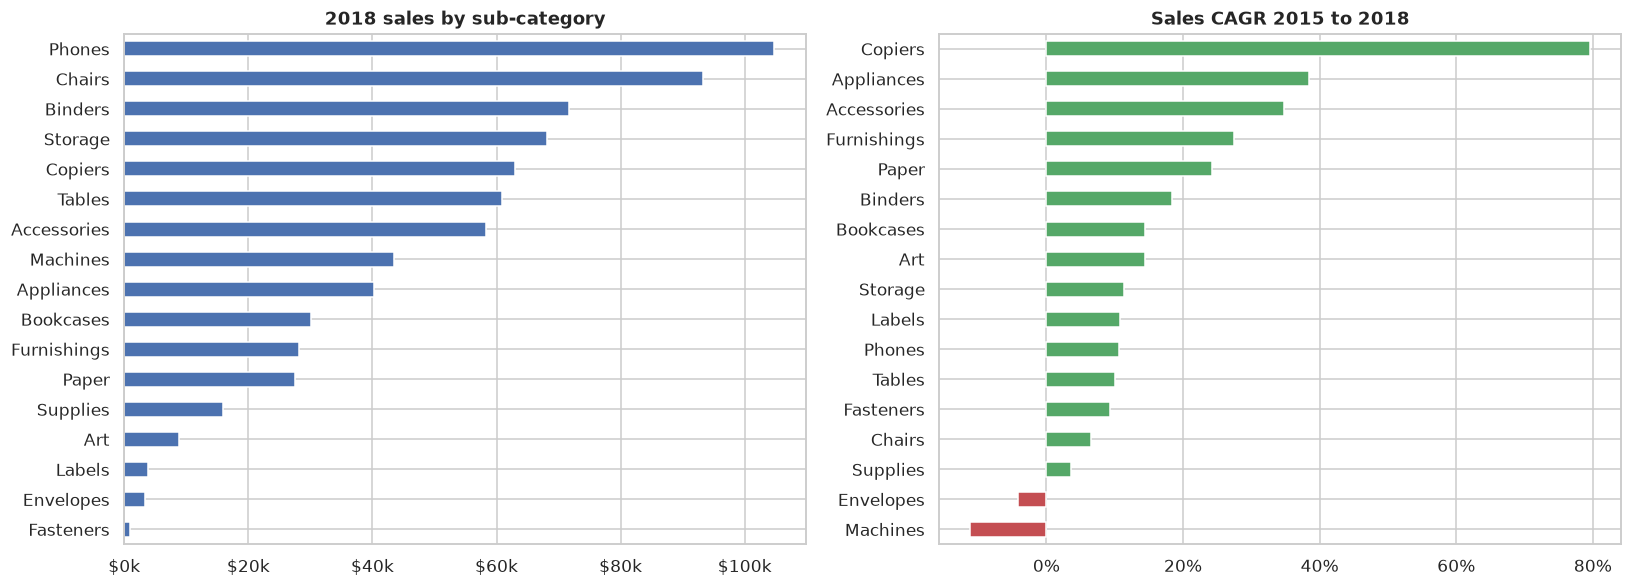

In [5]:
first, last = df["Year"].min(), df["Year"].max()
sub = df.pivot_table(index="Sub-Category", columns="Year", values="Sales", aggfunc="sum")
sub["Share"] = sub[last] / sub[last].sum()
sub["Growth vs prior year"] = sub[last] / sub[last - 1] - 1
sub["CAGR"] = (sub[last] / sub[first]) ** (1 / (last - first)) - 1
sub = sub.sort_values(last, ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
sub[last][::-1].plot.barh(ax=axes[0], color="#4c72b0"); axes[0].xaxis.set_major_formatter(money); axes[0].set_title(f"{last} sales by sub-category"); axes[0].set_ylabel("")
sub["CAGR"].sort_values().plot.barh(ax=axes[1], color=np.where(sub["CAGR"].sort_values() > 0, "#55a868", "#c44e52"))
axes[1].xaxis.set_major_formatter(mtick.PercentFormatter(1.0)); axes[1].set_title(f"Sales CAGR {first} to {last}"); axes[1].set_ylabel("")
plt.tight_layout(); plt.show()

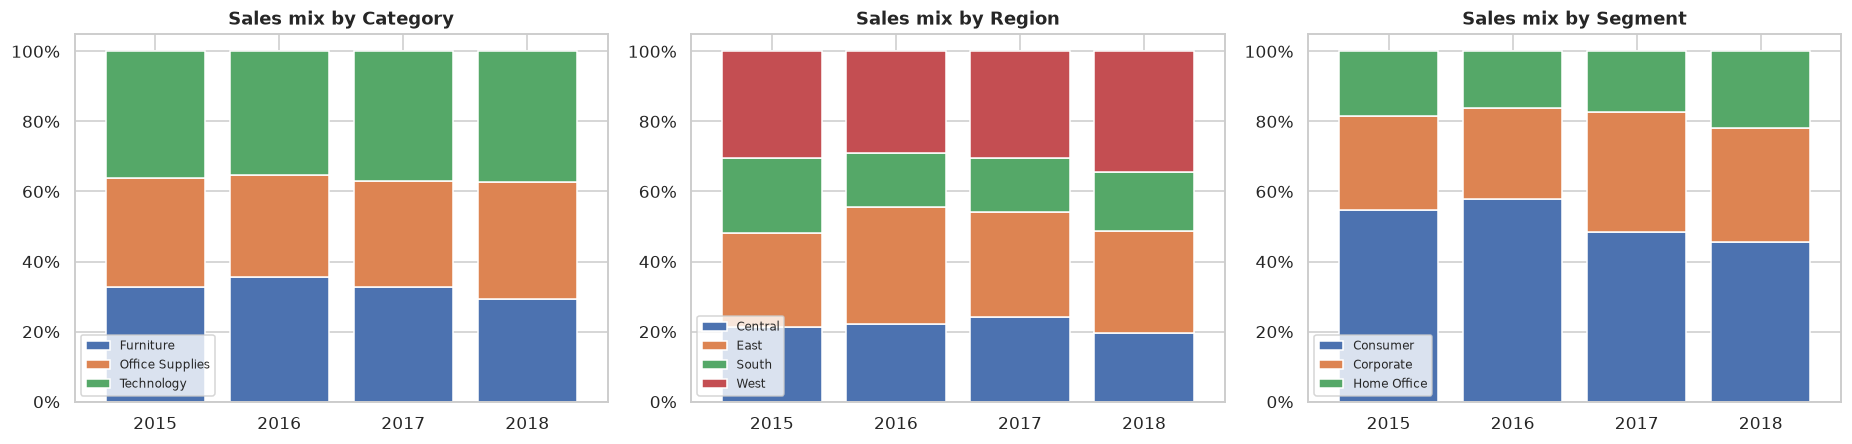

Region growth in the latest year: Central -3%, East +18%, South +31%, West +36%


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
for ax, dim in zip(axes, ["Category", "Region", "Segment"]):
    p = df.pivot_table(index="Year", columns=dim, values="Sales", aggfunc="sum")
    (p.div(p.sum(axis=1), axis=0)).plot.bar(stacked=True, ax=ax, width=0.8)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax.set_title(f"Sales mix by {dim}"); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=0)
    ax.legend(fontsize=8, loc="lower left")
plt.tight_layout(); plt.show()

reg = df.pivot_table(index="Region", columns="Year", values="Sales", aggfunc="sum")
reg_g = (reg[last] / reg[last - 1] - 1).sort_values()
print("Region growth in the latest year: " + ", ".join(f"{r} {v:+.0%}" for r, v in reg_g.items()))

## 4. Operations: shipping lead time

,orders,avg_days,p90_days,order_share
Ship Mode,,,,
Same Day,261,0.0,0,5.3%
First Class,772,2.2,3,15.7%
Second Class,944,3.2,5,19.2%
Standard Class,2945,5.0,7,59.8%


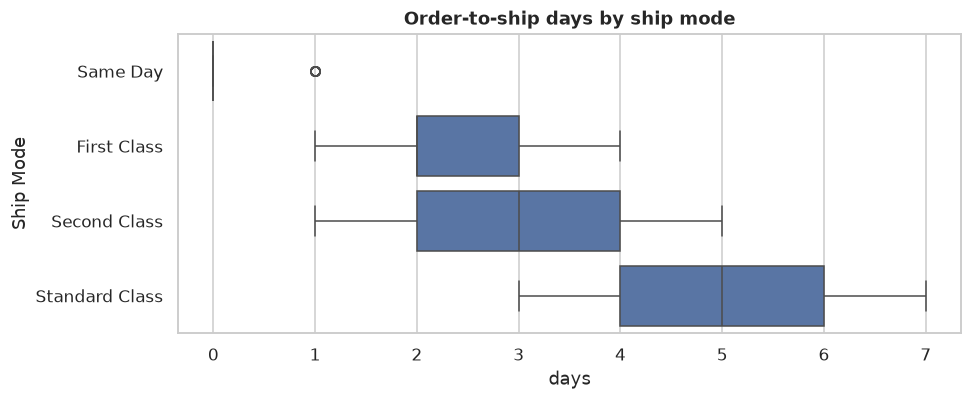

In [7]:
ship = df.drop_duplicates("Order ID").groupby("Ship Mode").agg(orders=("Order ID", "size"), avg_days=("LeadTime", "mean"), p90_days=("LeadTime", lambda s: s.quantile(0.9)))
ship["order_share"] = ship["orders"] / ship["orders"].sum()
display(ship.sort_values("avg_days").style.format({"avg_days": "{:.1f}", "p90_days": "{:.0f}", "order_share": "{:.1%}"}))
fig, ax = plt.subplots(figsize=(9, 3.8))
sns.boxplot(data=df.drop_duplicates("Order ID"), x="LeadTime", y="Ship Mode", order=ship.sort_values("avg_days").index, ax=ax)
ax.set_title("Order-to-ship days by ship mode"); ax.set_xlabel("days")
plt.tight_layout(); plt.show()

## 5. Forecasting next year's monthly sales
**Backtest:** train on all but the last 12 months, forecast those 12, and compare with the actuals using MAPE and the error on the yearly total (what finance cares about).

Models:
- **Seasonal naive** (baseline): same month last year
- **Holt-Winters** on log sales (trend + seasonality, i.e. multiplicative effects in sales terms)
- **SARIMA(1,1,1)(0,1,1,12)** on log sales

,MAPE,annual total error
model,,
Holt-Winters,20.8%,-1.0%
Seasonal naive,24.9%,-16.9%
SARIMA,25.1%,+2.6%


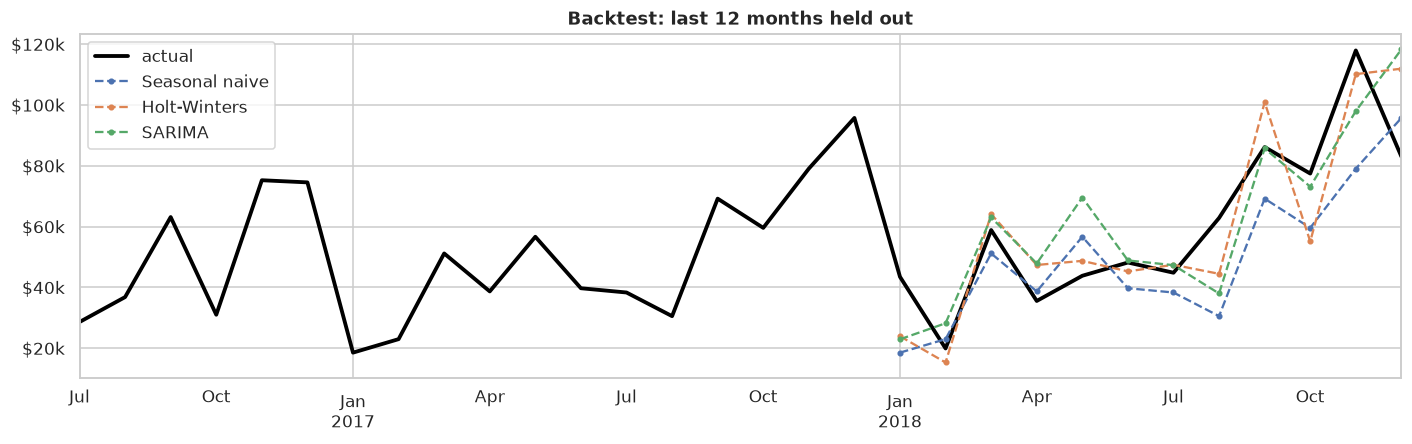

In [8]:
train, test = monthly[:-12], monthly[-12:]

def fc_naive(tr, h=12): return pd.Series(tr[-12:].values[:h], index=pd.date_range(tr.index[-1] + pd.offsets.MonthBegin(), periods=h, freq="MS"))
def fc_hw(tr, h=12): return np.exp(ExponentialSmoothing(np.log(tr), trend="add", seasonal="add", seasonal_periods=12).fit(optimized=True).forecast(h))
def fc_sarima(tr, h=12):
    m = SARIMAX(np.log(tr), order=(1, 1, 1), seasonal_order=(0, 1, 1, 12)).fit(disp=False)
    return np.exp(m.get_forecast(h).predicted_mean)

models = {"Seasonal naive": fc_naive, "Holt-Winters": fc_hw, "SARIMA": fc_sarima}
preds, scores = {}, []
for name, f in models.items():
    p = f(train); p.index = test.index; preds[name] = p
    scores.append({"model": name, "MAPE": np.mean(np.abs(p - test) / test),
                   "annual total error": p.sum() / test.sum() - 1})
scores = pd.DataFrame(scores).set_index("model").sort_values("MAPE")
display(scores.style.format({"MAPE": "{:.1%}", "annual total error": "{:+.1%}"}).highlight_min(subset=["MAPE"], color="#c7e9c0"))

fig, ax = plt.subplots(figsize=(13, 4.2))
monthly[-30:].plot(ax=ax, color="black", lw=2.5, label="actual")
for name, p in preds.items(): p.plot(ax=ax, ls="--", marker=".", label=name)
ax.yaxis.set_major_formatter(money); ax.set_title("Backtest: last 12 months held out"); ax.set_xlabel(""); ax.legend()
plt.tight_layout(); plt.show()

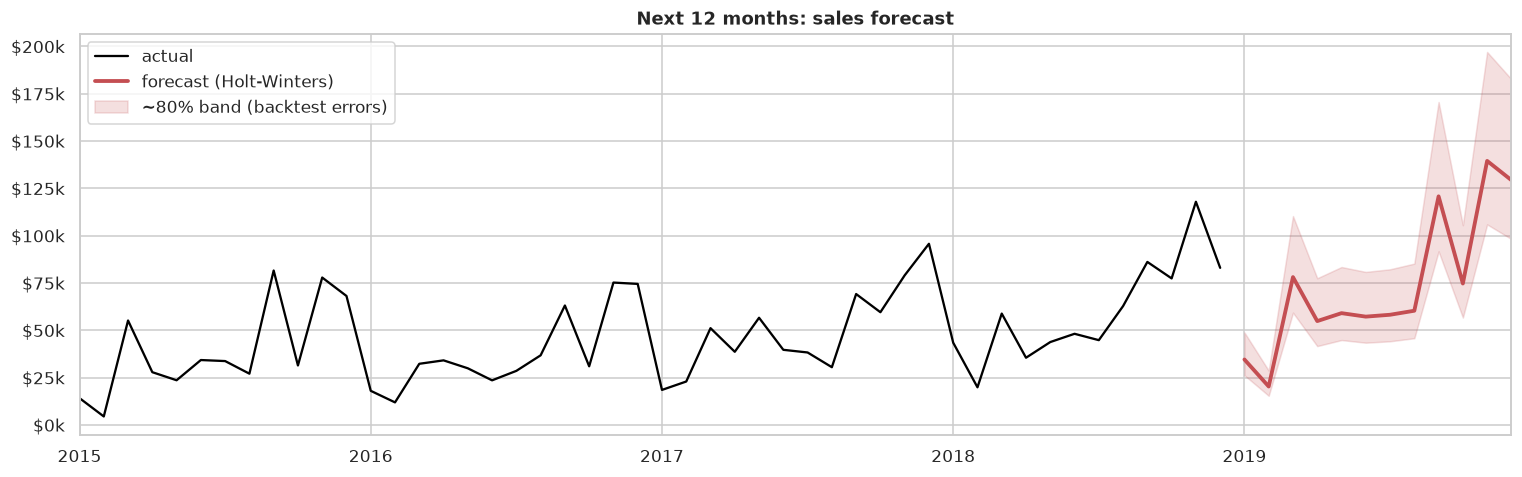

,forecast,low,high
Jan 2019,"$34,607","$26,284","$48,877"
Feb 2019,"$20,348","$15,454","$28,738"
Mar 2019,"$78,136","$59,345","$110,355"
Apr 2019,"$54,899","$41,696","$77,536"
May 2019,"$59,092","$44,881","$83,459"
Jun 2019,"$57,259","$43,489","$80,870"
Jul 2019,"$58,244","$44,237","$82,261"
Aug 2019,"$60,371","$45,852","$85,265"
Sep 2019,"$120,801","$91,749","$170,613"
Oct 2019,"$74,739","$56,765","$105,558"


Best model: Holt-Winters (backtest MAPE 20.8%, annual total error -1.0%).
Next-12-month sales forecast: $887,379 vs $722,052 in the last 12 months (+22.9%).


In [9]:
best = scores.index[0]
final = models[best](monthly)
# Uncertainty band from backtest errors: percentage errors applied to the forecast (empirical 80% band)
pct_err = (preds[best] - test) / test
lo_q, hi_q = np.quantile(pct_err, [0.1, 0.9])
lower, upper = final / (1 + hi_q), final / (1 + lo_q)

fig, ax = plt.subplots(figsize=(14, 4.5))
monthly.plot(ax=ax, color="black", label="actual")
final.plot(ax=ax, color="#c44e52", lw=2.5, label=f"forecast ({best})")
ax.fill_between(final.index, lower, upper, color="#c44e52", alpha=0.18, label="~80% band (backtest errors)")
ax.yaxis.set_major_formatter(money); ax.set_title("Next 12 months: sales forecast"); ax.set_xlabel(""); ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

plan = pd.DataFrame({"forecast": final, "low": lower, "high": upper})
plan.index = plan.index.strftime("%b %Y")
display(plan.style.format("${:,.0f}"))
print(f"Best model: {best} (backtest MAPE {scores.loc[best, 'MAPE']:.1%}, annual total error {scores.loc[best, 'annual total error']:+.1%}).")
print(f"Next-12-month sales forecast: ${final.sum():,.0f} vs ${monthly[-12:].sum():,.0f} in the last 12 months ({final.sum() / monthly[-12:].sum() - 1:+.1%}).")

## 6. Takeaways
- **Read the KPI tiles first:** the yearly table splits sales growth into order volume and basket size (AOV). Those two call for different levers (traffic and acquisition vs. bundles and pricing).
- **Seasonality is strong.** Most of the year's revenue lands in the Q4 peak months, so inventory, staffing and ad budgets should ramp up from September.
- **Mix matters.** A few sub-categories make up most of the revenue, and the CAGR chart shows which ones are growing vs. declining. Use it to decide where to put assortment and marketing.
- **Forecast for planning, not promises.** Monthly sales are noisy, so the annual total is far more reliable than any single month. Plan inventory to the forecast and keep safety stock near the upper band in peak months.

**Next steps:** add profit/margin and returns data, forecast by category (bottom-up) to reconcile with the top-down total, and refresh the backtest monthly.

*If this KPI pack template is useful, an upvote is appreciated. Comments and suggestions are welcome.*

---
**Shahzad Raza** · E-commerce & marketing data analyst · [GitHub](https://github.com/Shahzrazaa) · [LinkedIn](https://www.linkedin.com/in/shahzadrazaa/)

📋 Free Amazon listing health checklist: https://adsmithai.gumroad.com/l/rxzumn

More notebooks: https://www.kaggle.com/shahzadrazaa/code